# Pathway-guided population programs

Figure 6: load the released OneK1K and AIDA models, infer program memberships and activity, and compute program alignment before plotting.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='IProgress not found.*')
from pathlib import Path
import json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon, pearsonr
from scdecage.tutorials_utils.plotting import DATA_ROOT, setup, output, letter, show_figure
DATA = Path('outputs/model_analyses/pathway_programs')
OUT = Path('outputs/figures')
OUT.mkdir(parents=True, exist_ok=True)
BLUE, PALE, GREY, SALMON = '#648DA3', '#C6DEE8', '#B8B8B2', '#CD886E'
setup()
PLOT_CONFIG = {'export_dpi': 800, 'display_width_fraction': 0.45, 'display_width_px': 480,
               'inline_max_pixels': [1100, 1600], 'bootstrap_draws': 2000,
               'cell_budget': 500, 'figure': 'Figure6', 'datasets': ['OneK1K', 'AIDA']}

## Model inference

Extract the Zenodo data and set `SCDECAGE_RELEASE_DATA` to its `data` directory.

In [2]:
import torch
from scdecage.tutorials_utils.inference import load_analysis_model, infer_donor
from scdecage.tutorials_utils.calculations import top_cell_prior_enrichment

def analyze_programs(model, donor_data, directory):
    directory.mkdir(parents=True, exist_ok=True)
    names = json.loads((DATA_ROOT / donor_data.dataset_dir.name / 'pathway_names.json').read_text())
    routes = model.aggregator.pathway_routes().detach().float().cpu().numpy()
    activities, memberships, compatibilities, signatures, controls = [], [], [], [], []
    offsets = [0]
    rng = np.random.default_rng()
    for item in donor_data:
        _, _, pathways, _, result = infer_donor(model, item)
        aux = result['aux']
        membership = aux['program_membership'].float().cpu().numpy()
        compatibility = aux['pathway_compatibility'].float().cpu().numpy()
        contribution = aux['normalized_cell_contributions'].float().cpu().numpy()
        activity = pathways.float().cpu().numpy()
        memberships.append(membership)
        compatibilities.append(compatibility)
        offsets.append(offsets[-1] + len(membership))
        signatures.append(contribution.T @ activity)
        randomized = np.column_stack([rng.permutation(contribution[:, k]) for k in range(64)])
        controls.append(randomized.T @ activity)
        for program, value in enumerate(aux['mean_prior_compatibility'].float().cpu().numpy()):
            activities.append({'donor_id': item['donor_id'], 'age_years': float(item['age']),
                               'program': program, 'activity': float(value)})
    enrichment = top_cell_prior_enrichment(np.concatenate(memberships),
        np.concatenate(compatibilities), np.asarray(offsets)).mean(0)
    pd.DataFrame(activities).to_csv(directory / 'program_activity.csv', index=False)
    for filename, values, columns in [
        ('program_routes.csv', routes, names),
        ('program_signatures.csv', np.mean(signatures, axis=0), names),
        ('random_program_signatures.csv', np.mean(controls, axis=0), names),
        ('prior_enrichment.csv', enrichment, [f'P{k:02d}' for k in range(64)])]:
        table = pd.DataFrame(values.astype(np.float64), columns=columns)
        table.index.name = 'program'
        table.to_csv(directory / filename, float_format='%.17g')
    (directory / 'pathway_names.json').write_text(json.dumps(names))

CHECKPOINTS = {name: DATA_ROOT / name / 'model.pth' for name in ['OneK1K', 'AIDA']}
for name, checkpoint in CHECKPOINTS.items():
    model, donor_data = load_analysis_model(name, checkpoint=checkpoint)
    analyze_programs(model, donor_data, DATA / name)


## Analysis calculations


In [3]:
def mean_ci(values, random_state=random.randrange(2 ** 32)):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    rng = np.random.default_rng(random_state)
    boot = rng.choice(values, (PLOT_CONFIG['bootstrap_draws'], len(values)), replace=True).mean(1)
    return (values.mean(), *np.quantile(boot, [0.025, 0.975]))
from pathlib import Path
import json
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import maximum_bipartite_matching
from scipy.spatial.distance import pdist
from scipy.stats import gaussian_kde, spearmanr

def normalize(matrix):
    lo, hi = np.nanpercentile(matrix, [1, 99])
    return np.clip((matrix - lo) / (hi - lo + 1e-12), 0, 1)

def render_figure6(root, output_figure, mean_ci, letter):
    settings = PLOT_CONFIG
    directory = OUT / 'figure6'
    directory.mkdir(exist_ok=True)
    BLUE = '#648DA3'
    GREY = '#B8B8B2'
    SALMON = '#CD886E'
    data = {}
    for dataset in ['OneK1K', 'AIDA']:
        source = Path(root) / dataset
        def matrix_table(filename):
            return pd.read_csv(source / filename, index_col='program', float_precision='round_trip').to_numpy()
        route = matrix_table('program_routes.csv')
        sig = matrix_table('program_signatures.csv')
        matrix = matrix_table('prior_enrichment.csv')
        names = json.loads((source / 'pathway_names.json').read_text())
        activity = pd.read_csv(source / 'program_activity.csv', dtype={'donor_id': str}, float_precision='round_trip')
        support = route > 0
        match = maximum_bipartite_matching(csr_matrix(support), perm_type='column')
        assert len(match) == 64 and (match >= 0).all() and (len(set(match)) == 64)
        owners = {int(col): row for row, col in enumerate(match)}
        for col in np.flatnonzero(support.any(0)):
            if int(col) not in owners:
                owners[int(col)] = int(np.flatnonzero(support[:, col])[0])
        columns = np.array(sorted(owners, key=lambda col: (owners[col], col != match[owners[col]], col)))
        assert len(set(columns)) == int(support.any(0).sum())
        assert np.array_equal(support[:, columns].sum(1), support.sum(1))
        anchor_positions = [int(np.flatnonzero(columns == c)[0]) for c in match]
        assert np.all(np.diff(anchor_positions) > 0)
        data[dataset] = {'route': route, 'names': names, 'activity': activity, 'align': normalize(matrix), 'cols': columns, 'anchors': anchor_positions, 'real': pdist(sig, metric='cosine') * 1000, 'random': pdist(matrix_table('random_program_signatures.csv'), metric='cosine') * 1000}
    for dataset, d in data.items():
        chosen = []
        titles = []
        selected = []
        for item in {'OneK1K': [{'program': 8, 'pathway': 'REACTOME_SENESCENCE_ASSOCIATED_SECRETORY_PHENOTYPE_SASP', 'title': 'Program P08\nSASP'}, {'program': 2, 'pathway': 'REACTOME_MHC_CLASS_II_ANTIGEN_PRESENTATION', 'title': 'Program P02\nMHC II'}, {'program': 22, 'pathway': 'REACTOME_INTERLEUKIN_10_SIGNALING', 'title': 'Program P22\nIL-10'}, {'program': 14, 'pathway': 'REACTOME_ADAPTIVE_IMMUNE_SYSTEM', 'title': 'Program P14\nAdaptive immunity'}], 'AIDA': [{'program': 51, 'pathway': 'REACTOME_PD_1_SIGNALING', 'title': 'Program P51\nPD-1 signaling'}, {'program': 3, 'pathway': 'REACTOME_INTERFERON_GAMMA_SIGNALING', 'title': 'Program P03\nInterferon-gamma'}, {'program': 42, 'pathway': 'REACTOME_CELLULAR_SENESCENCE', 'title': 'Program P42\nCellular senescence'}, {'program': 39, 'pathway': 'REACTOME_BASE_EXCISION_REPAIR', 'title': 'Program P39\nBase-excision repair'}]}[dataset]:
            program = item['program']
            name = item['pathway']
            index = d['names'].index(name)
            assert d['route'][program, index] > 0 and program not in chosen
            chosen.append(program)
            titles.append(item['title'])
            selected.append({'program': program, 'representative_prior': name, 'prior_weight': float(d['route'][program, index])})
        d.update(chosen=chosen, titles=titles, A_activity=d['activity'])
    for dataset, d in data.items():
        results = {}
        for program in d['chosen']:
            g = d['A_activity'][d['A_activity'].program.eq(program)]
            assert g.donor_id.is_unique
            test = spearmanr(g.age_years.to_numpy(), g.activity.to_numpy(), alternative='two-sided')
            results[program] = {'program': program, 'n_donors': len(g), 'rho': float(test.statistic), 'p_value': float(test.pvalue)}
        d['age_associations'] = results
    palette = LinearSegmentedColormap.from_list('programs64', ['#588DAD', '#82B9CC', '#70A185', '#D5AA58', '#CB8167', '#D49AA3', '#9B88BA', '#6F817B'])(np.linspace(0, 1, 64))

    def panel_a(fig, slot):
        for row, (dataset, d) in enumerate(data.items()):
            activity = d['A_activity']
            ages = activity[['donor_id', 'age_years']].drop_duplicates()
            cuts = ages.age_years.quantile([0.25, 0.5, 0.75]).to_numpy()
            for col, k in enumerate(d['chosen']):
                ax = fig.add_subplot(slot[row, col])
                g = activity[activity.program.eq(k)]
                z = (g.activity - g.activity.mean()) / (g.activity.std() + 1e-08)
                q = np.searchsorted(cuts, g.age_years, side='right')
                mu, lo, hi = np.array([mean_ci(z.to_numpy()[q == i], random.randrange(2 ** 32) + i) for i in range(4)]).T
                association = d['age_associations'][k]
                pvalue = association['p_value']
                ax.errorbar(range(4), mu, yerr=[mu - lo, hi - mu], fmt='o-', ms=3, lw=1.2, c='#CD886E', capsize=2)
                lower = min(float(lo.min()), 0.0)
                upper = max(float(hi.max()), 0.0)
                span = max(upper - lower, 0.1)
                ax.set_ylim(lower - 0.06 * span, upper + 0.25 * span)
                mantissa, exponent = f'{pvalue:.2e}'.split('e')
                label = f'$P = {mantissa}\\times10^{{{int(exponent)}}}$'
                ax.text(0.025, 0.975, label, transform=ax.transAxes, va='top', fontsize=8, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.2})
                ax.axhline(0, c='#9A9EA2', ls='--', lw=0.6)
                ax.set_xticks(range(4), ['Q1', 'Q2', 'Q3', 'Q4'])
                ax.tick_params(labelsize=8)
                ax.set_title(f"P{k:02d}: {d['titles'][col].splitlines()[-1]}", fontsize=7.5, pad=6)
                ax.grid(axis='y')
                if col == 0:
                    ax.set_ylabel(dataset + '\nProgram score (z)', fontsize=8.5)
                if row == col == 0:
                    letter(ax, 'A', -0.35)

    def panel_b(fig, slot):
        for row, (dataset, d) in enumerate(data.items()):
            ax = fig.add_subplot(slot[row, 0])
            support = d['route'][:, d['cols']] > 0
            pixels = support * (np.arange(64)[:, None] + 1)
            ax.imshow(pixels, cmap=ListedColormap(np.vstack([[1, 1, 1, 1], palette])), vmin=0, vmax=64, interpolation='nearest', aspect='auto')
            assert (pixels > 0).sum() == 512
            ax.set_yticks(range(0, 64, 8), [f'P{k:02d}' for k in range(0, 64, 8)])
            ax.set_xticks([])
            ax.set_title(f"{dataset} (n={len(d['cols'])})", fontsize=10)
            ax.set_ylabel('Program', fontsize=9)
            ax.set_xlabel('Ordered Reactome pathways', fontsize=8)
            ax.tick_params(labelsize=8)
            for r in range(8, 64, 8):
                x = d['anchors'][r] - 0.5
                ax.axvline(x, c='#E5E7E9', lw=0.6, zorder=0)
            if row == 0:
                letter(ax, 'B', -0.12)

    def panel_c(fig, slot, horizontal=True):
        for row, (dataset, d) in enumerate(data.items()):
            ax = fig.add_subplot(slot[0, row] if horizontal else slot[row, 0])
            im = ax.imshow(d['align'], cmap=sns.color_palette('mako', as_cmap=True), vmin=0, vmax=1, aspect='equal', interpolation='nearest')
            ax.set_xticks(range(0, 64, 8))
            ax.set_yticks(range(0, 64, 8))
            ax.tick_params(labelsize=8)
            ax.set_title(dataset, fontsize=10)
            ax.set_xlabel('Pathway program', fontsize=9)
            ax.set_ylabel('Cell-routing program', fontsize=9)
            if horizontal and row > 0:
                ax.set_ylabel('')
                ax.tick_params(axis='y', labelleft=False)
            if row == 1:
                cax = ax.inset_axes([1.025, 0, 0.045, 1])
                cb = fig.colorbar(im, cax=cax)
                cb.set_label('Normalized alignment', fontsize=9)
                cb.ax.tick_params(labelsize=8)
            if row == 0:
                letter(ax, 'C', -0.19)

    def panel_d(fig, slot):
        rng = np.random.default_rng(random.randrange(2 ** 32))
        for col, (dataset, d) in enumerate(data.items()):
            ax = fig.add_subplot(slot[0, col])
            b = ax.boxplot([d['real'], d['random']], patch_artist=True, showfliers=False, widths=0.5, medianprops={'color': 'black'})
            for patch, color in zip(b['boxes'], [BLUE, GREY]):
                patch.set_facecolor(color)
                patch.set_alpha(0.7)
            for i, key in enumerate(['real', 'random'], 1):
                values = d[key]
                values = values[values <= 0.006]
                take = rng.choice(len(values), min(600, len(values)), replace=False)
                ax.scatter(i + rng.normal(0, 0.045, len(take)), values[take], s=3, c=BLUE, alpha=0.15, rasterized=True)
            ax.set_ylim(0, 0.006)
            ax.set_xticks([1, 2], ['scDecAge\nprograms', 'Random\nprograms'], fontsize=8)
            ax.set_title(dataset, fontsize=10)
            ax.grid(axis='y')
            if col == 0:
                ax.set_ylabel('Pairwise cosine distance ($\\times10^{-3}$)', fontsize=9)
                letter(ax, 'D', -0.25)

    def panel_e(fig, slot):
        rng = np.random.default_rng(random.randrange(2 ** 32))
        for row, (dataset, d) in enumerate(data.items()):
            ax = fig.add_subplot(slot[row, 0])
            within = np.diag(d['align'])
            cross = (d['align'].sum(1) - within) / 63
            points = []
            for i, (values, color) in enumerate([(within, BLUE), (cross, GREY)]):
                if np.std(values) > 1e-07:
                    y = np.linspace(max(0, values.min() - 0.05), min(1, values.max() + 0.05), 160)
                    density = gaussian_kde(values)(y)
                    ax.fill_betweenx(y, i - 0.12, i - 0.12 - 0.25 * density / density.max(), color=color, alpha=0.5, lw=0)
                x = i + rng.normal(0.07, 0.035, len(values))
                points.append(x)
                ax.scatter(x, values, s=8, c=color, alpha=0.65, zorder=4)
            for x1, x2, a, b in zip(*points, within, cross):
                ax.plot([x1, x2], [a, b], c=BLUE, lw=0.4, alpha=0.18, zorder=2)
            ax.boxplot([within, cross], positions=[0, 1], widths=0.13, showfliers=False, zorder=5, medianprops={'color': 'black'})
            ax.set_xticks([0, 1], ['Within-program', 'Cross-program'], fontsize=8)
            ax.set_ylim(0, 1.04)
            ax.set_title(dataset, fontsize=10)
            ax.set_ylabel('Normalized enrichment', fontsize=9)
            ax.grid(axis='y')
            if row == 0:
                letter(ax, 'E', -0.2)
    for label, fn, shape, size in [('A', panel_a, (2, 4), tuple([14.3, 6.7])), ('B', panel_b, (2, 1), (6.8, 5.8)), ('C', panel_c, (1, 2), (8.0, 4.2)), ('D', panel_d, (1, 2), (7.6, 3.52)), ('E', panel_e, (2, 1), (7.5, 6.4))]:
        fig = plt.figure(figsize=size)
        fn(fig, fig.add_gridspec(*shape, hspace=0.65, wspace=0.38))
        output_figure(fig, directory, 'Figure6' + label)


## Age-associated programs

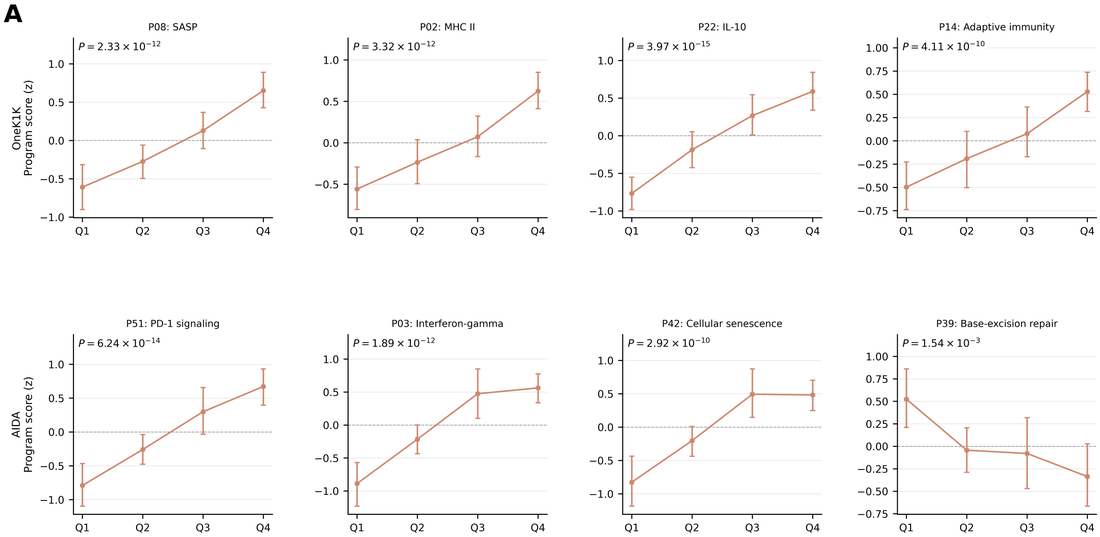

In [4]:
render_figure6(DATA, output, mean_ci, letter)
show_figure(OUT / 'figure6/Figure6A.png')


## Program pathway supports

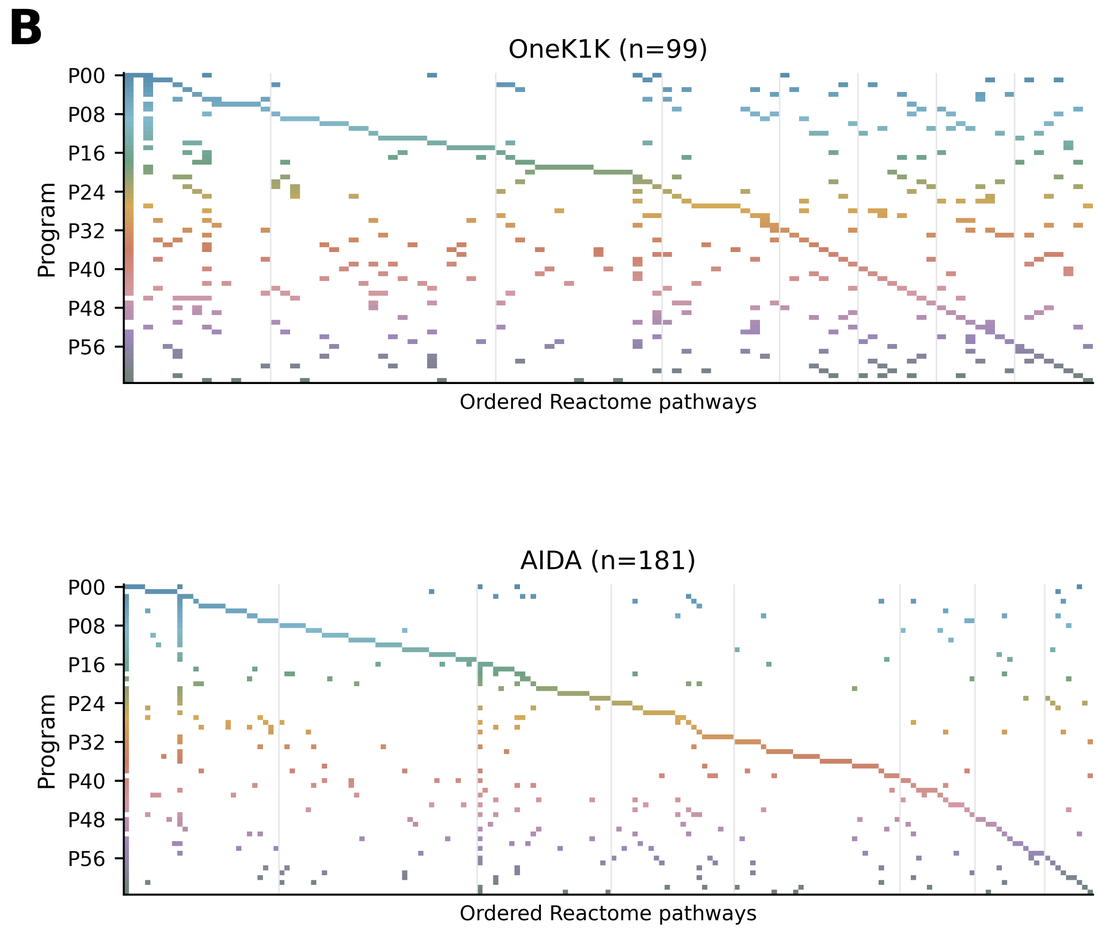

In [5]:
show_figure(OUT / 'figure6/Figure6B.png')


## Prior-activity enrichment

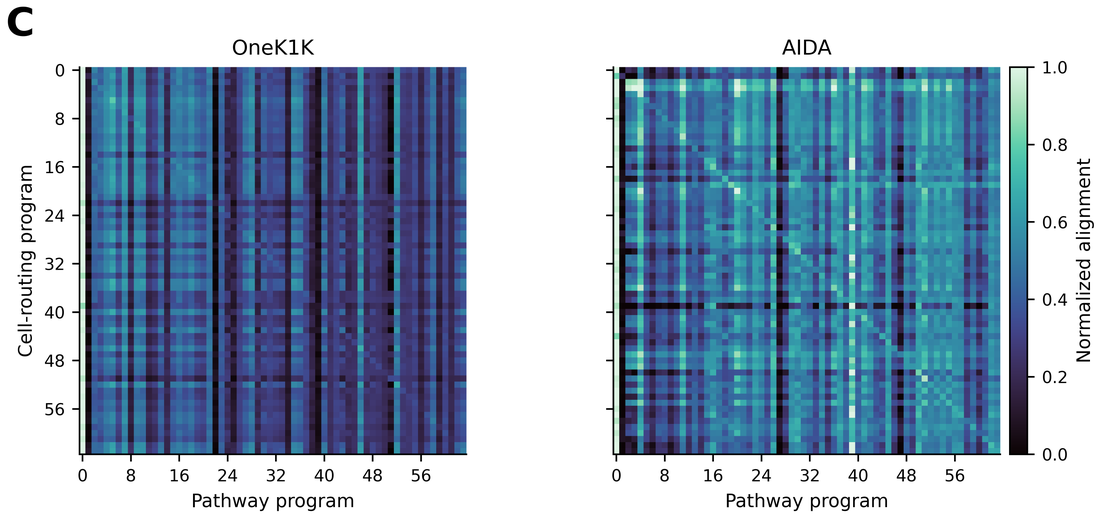

In [6]:
show_figure(OUT / 'figure6/Figure6C.png')


## Program diversity

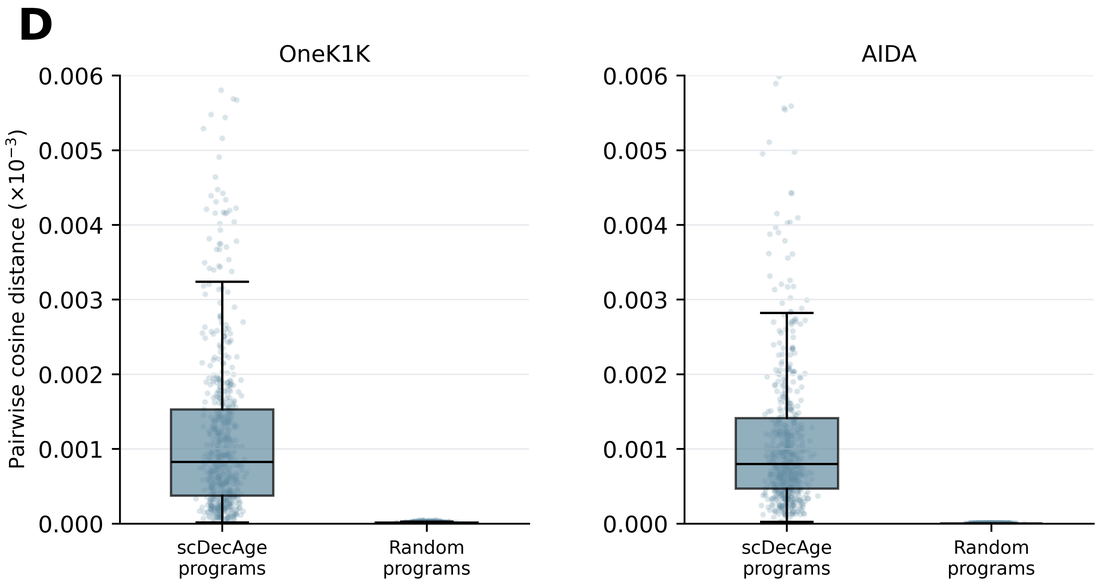

In [7]:
show_figure(OUT / 'figure6/Figure6D.png')


## Within- and cross-program enrichment

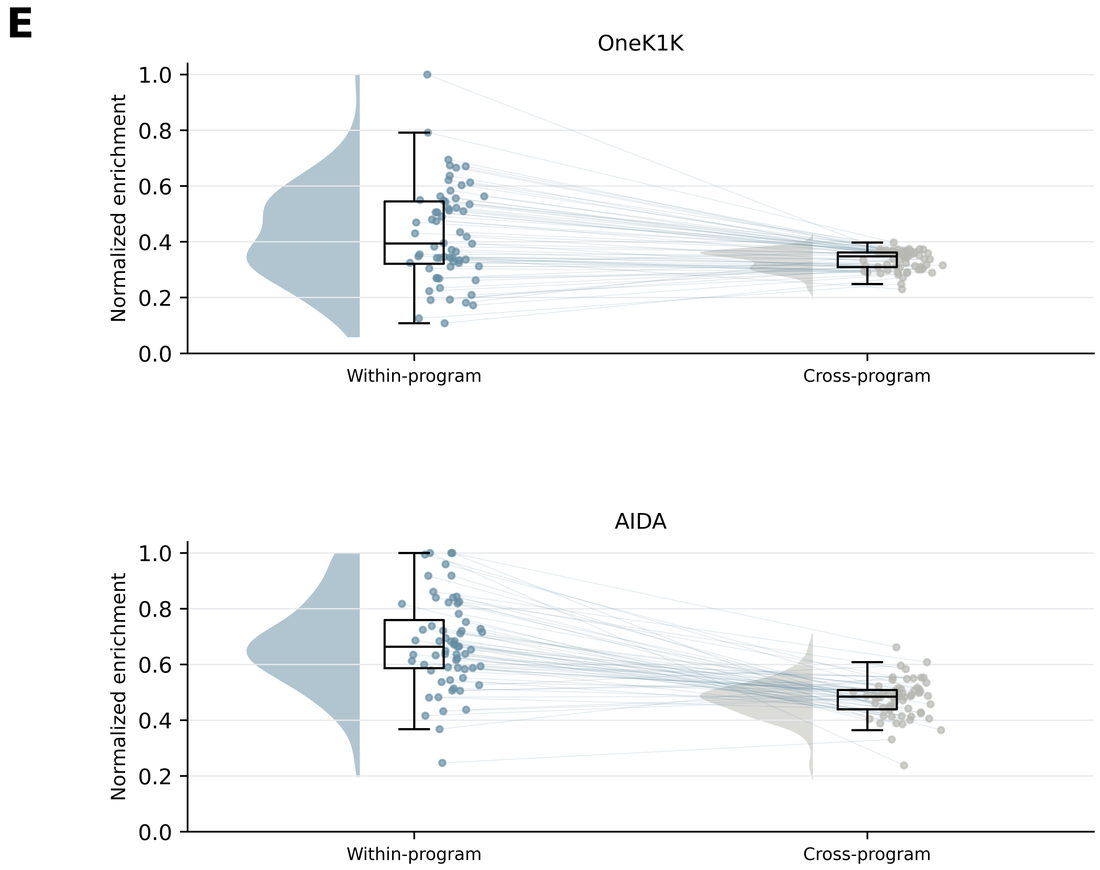

In [8]:
show_figure(OUT / 'figure6/Figure6E.png')
